# Part A: audit of `train.jsonl` (NimbusPay ticket triage)

This notebook finds what is wrong with the training data, decides what to do about each problem, and writes
`cleaning_log.csv` (`id,action,reason`) and `train_clean.jsonl`. Every finding is produced by code on this page,
every decision is logged per row, and a final gate re-checks every SCHEMA.md rule on every kept row.
Only `train.jsonl` and `SCHEMA.md` are used to decide labels; dev/test are only used to *detect* leakage
and to compare populations (never to change a label).

| Problem found | How it was found | Rows | Decision |
|---|---|---|---|
| Label JSON truncated | `json.loads` fails | 25 | drop (missing keys not recoverable) |
| Placeholder / empty ticket ("test", "asdf asdf", header only) | amount not found in text → read → regex | 10 | drop (label not grounded in input) |
| Ticket copied from **dev** (exact body / near-duplicate) | exact match + char n-gram cosine | 37 + 11 | drop (leakage) |
| Exact duplicate inside train | identical ticket | 60 | drop extra copies |
| Near-duplicate inside train (whitespace / "Thx") | cosine ≥ 0.95, same label | 40 | drop extra copies |
| Legacy key `prio: low/medium/high` | spec check | 70 | fix → `priority` P3/P2/P1 |
| `txn_date` as DD/MM/YYYY | spec check | 30 | fix → ISO date |
| `txn_id` not normalised (`np 81633 47892`) | spec check | 20 | fix → `NP` + 10 digits |
| `amount_paise` stored in rupees | amount parsed from text | 25 | fix → re-derived from the ticket |
| `priority` disagrees with the SCHEMA v2 rules | rules as code | 60 | fix → recomputed |

**Result: 1,445 → 1,262 rows; 183 dropped, 175 fixed (205 field fixes).** Category, channel, txn_id, txn_date,
needs_human and language were checked against the text and needed no changes. No test ticket appears in train.

## 0. Setup

In [1]:
# 0.1 Paths and data. On Colab the data lives in Drive; locally set VIMA_BASE to the folder that holds candidate_pack/.
import os, sys, re, json, csv, difflib, collections, datetime as dt
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/vima3ya'
else:
    BASE = os.environ.get('VIMA_BASE', '..')
DATA = f'{BASE}/candidate_pack/data'
OUT  = os.environ.get('PREP_OUT', f'{BASE}/prep_outputs')     # train_clean.jsonl, cleaning_log.csv, figures/
FIG  = f'{OUT}/figures'
os.makedirs(FIG, exist_ok=True)

def load_jsonl(path):
    with open(path, encoding='utf-8') as f:
        return [json.loads(line) for line in f if line.strip()]   # a corrupt LINE would crash here: that is a check too

train = load_jsonl(f'{DATA}/train.jsonl')
dev   = load_jsonl(f'{DATA}/dev.jsonl')
test  = load_jsonl(f'{DATA}/test_inputs.jsonl')
print(len(train), len(dev), len(test))

1445 200 400


In [2]:
# 0.2 Chart style: one fixed palette (slot order never changes), thin marks, quiet axes.
#     Every figure is also saved to prep_outputs/figures/ for the report.
BLUE, ORANGE, AQUA, LIGHT_BLUE = '#2a78d6', '#eb6834', '#1baf7a', '#9ec5f4'
INK, INK2, SURFACE, GRID = '#0b0b0b', '#52514e', '#fcfcfb', '#e6e5e0'
SPLIT_COLOR = {'train': BLUE, 'dev': ORANGE, 'test': AQUA}       # a split keeps its colour in every chart
SEQ = LinearSegmentedColormap.from_list('blue_seq', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK2, 'text.color': INK, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': GRID, 'grid.linewidth': 0.6, 'font.size': 9.5, 'axes.titlesize': 10.5, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'legend.frameon': False, 'figure.dpi': 110})

def save(fig, name):
    fig.savefig(f'{FIG}/{name}.png', dpi=160, bbox_inches='tight')
    plt.show()

In [3]:
# 0.3 One table per split: header (Received date, Source) split from the ticket body; labels parsed.
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)
HDR = re.compile(r'^Received: (\d{4}-\d{2}-\d{2}) \((\w{3})\)\nSource: ([\w-]+)\n\n')

def flatten(rows, split):
    recs = []
    for r in rows:
        user = r['messages'][1]['content']
        m = HDR.match(user)
        rec = dict(id=r['id'], split=split,
                   received=m.group(1) if m else None, weekday=m.group(2) if m else None,
                   source=m.group(3) if m else None, body=user[m.end():] if m else user, n_chars=len(user))
        if len(r['messages']) == 3:                                # test has no label
            raw = r['messages'][2]['content']
            rec['label_raw'] = raw
            try:
                rec['label'], rec['parse_ok'] = json.loads(raw), True
            except json.JSONDecodeError:
                rec['label'], rec['parse_ok'] = None, False
        recs.append(rec)
    return pd.DataFrame(recs)

tr, dv, ts = flatten(train, 'train'), flatten(dev, 'dev'), flatten(test, 'test')

first_part = lambda b: b.split('\n>')[0]          # the customer's own words, without quoted earlier emails
def norm_id(s):
    return re.sub(r'[^A-Za-z0-9]', '', s).upper()

def show(df, n=5, seed=0, ids=None, labels=True):
    """Print tickets to read them (the most useful check in this notebook)."""
    sub = df[df.id.isin(ids)] if ids else df.sample(min(n, len(df)), random_state=seed)
    for _, r in sub.iterrows():
        print('=' * 100)
        print(r.id, '|', r.received, r.weekday, '|', r.source, '|', r.n_chars, 'chars')
        print(r.body)
        if labels and isinstance(r.get('label_raw'), str):
            print('-->', r.label_raw)

## 1. First look: structure, sample tickets, populations

In [4]:
# 1.1 Is the structure the same everywhere? Do the headers and labels parse?
def structure_report(name, rows):
    C = collections.Counter
    ids = [r['id'] for r in rows]
    print(f'--- {name} ({len(rows)} rows) | keys {dict(C(tuple(r) for r in rows))} | duplicate ids {len(ids) - len(set(ids))}')
    print('    roles  :', dict(C(tuple(m['role'] for m in r['messages']) for r in rows)))
    print('    system :', C(r['messages'][0]['content'] for r in rows).most_common(1))

for n, r in [('train', train), ('dev', dev), ('test', test)]:
    structure_report(n, r)
for df in (tr, dv, ts):
    print(f'{df.split[0]:5} | header parsed {df.received.notna().mean():.0%} | sources {df.source.value_counts().to_dict()}')
print('\ntrain labels parse OK?', tr.parse_ok.value_counts().to_dict())
print('dev   labels parse OK?', dv.parse_ok.value_counts().to_dict())

--- train (1445 rows) | keys {('id', 'messages'): 1445} | duplicate ids 0
    roles  : {('system', 'user', 'assistant'): 1445}
    system : [("You are NimbusPay's ticket triage model. Read the ticket and return the triage JSON.", 1445)]
--- dev (200 rows) | keys {('id', 'messages'): 200} | duplicate ids 0
    roles  : {('system', 'user', 'assistant'): 200}
    system : [("You are NimbusPay's ticket triage model. Read the ticket and return the triage JSON.", 200)]
--- test (400 rows) | keys {('id', 'messages'): 400} | duplicate ids 0
    roles  : {('system', 'user'): 400}
    system : [("You are NimbusPay's ticket triage model. Read the ticket and return the triage JSON.", 400)]
train | header parsed 100% | sources {'app-chat': 658, 'email': 363, 'twitter': 233, 'ivr-transcript': 191}
dev   | header parsed 100% | sources {'app-chat': 86, 'email': 44, 'twitter': 40, 'ivr-transcript': 30}
test  | header parsed 100% | sources {'app-chat': 165, 'email': 110, 'twitter': 73, 'ivr-transcript':

In [5]:
# 1.2 Read tickets: two per source
for src in ['app-chat', 'email', 'twitter', 'ivr-transcript']:
    sub = tr[tr.source == src]
    print('\n' + '#' * 30, src.upper(), f'({len(sub)} train rows)', '#' * 30)
    show(sub, n=2, seed=2)


############################## APP-CHAT (658 train rows) ##############################
tr-00580 | 2026-07-27 Mon | app-chat | 97 chars
Hi team, My PIN was blocked. Waiting for your reply.
--> {"category": "account_access", "priority": "P2", "amount_paise": null, "txn_date": null, "txn_id": null, "channel": null, "language": "en", "needs_human": false}
tr-00493 | 2026-06-28 Sun | app-chat | 283 chars
Good morning, What can I do about some payments on my card I didn't make. Please put a freeze on my card till we can figure this out. The txn id is np0733824857. 602 rupees is the amount. My phone is a iPhone 13. Kindly resolve this asap.
--> {"category": "fraud", "priority": "P1", "amount_paise": 60200, "txn_date": null, "txn_id": "NP0733824857", "channel": "card", "language": "en", "needs_human": true}

############################## EMAIL (363 train rows) ##############################
tr-00243 | 2026-07-23 Thu | email | 280 chars
Subject: Issue with my account

Good morning,
I request

What reading tickets showed (each became a check below):
- **English and Hinglish** (`hi-en`) tickets; Hinglish uses words like *paise kat gaye*, *parso*, *din pehle*.
- **Several amounts per ticket**: the claim amount plus distractors (account balance, daily limit, fees).
- **Relative dates** ("day before yesterday", "4 days ago", *parso*) that must be resolved from the Received date.
- **Transaction ids in many spellings**: `NP-7780044598`, `np 81633 47892`, `NP 6949410784`.
- **Emails with quoted earlier messages** (`> ...`): text that is not the customer's current request.
- **Prior-contact phrases** ("third time I am contacting you", *teesri baar*) that drive `needs_human`.

Source share per split (%):
source  app-chat  email  ivr-transcript  twitter
split                                           
dev         43.0   22.0            15.0     20.0
test        41.2   27.5            13.0     18.2
train       45.5   25.1            13.2     16.1 

Ticket length (chars):
        count    50%    90%     99%     max
split                                      
dev     200.0  201.0  284.0  6098.0  8807.0
test    400.0  210.0  307.0  7654.0  8719.0
train  1445.0  196.0  283.0  7156.0  8839.0 

Share of tickets with quoted earlier emails: {'dev': 0.015, 'test': 0.028, 'train': 0.028}


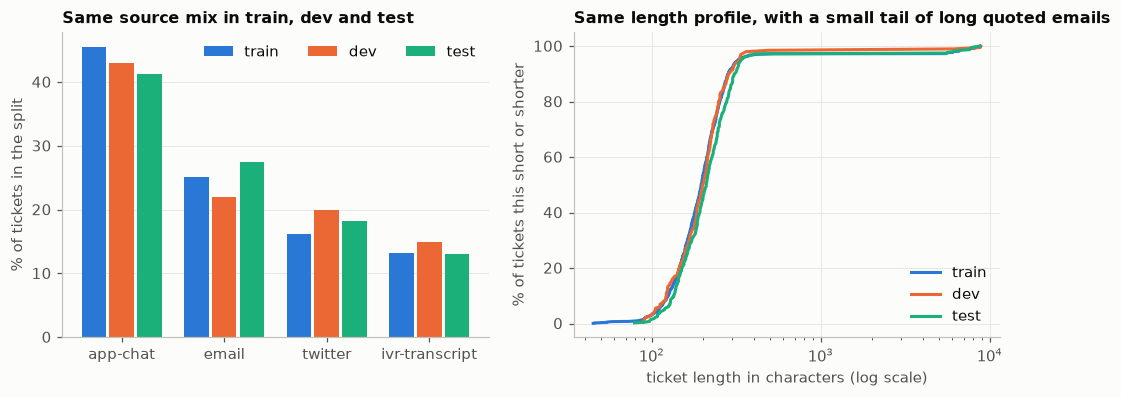

In [6]:
# 1.3 Are train, dev and test from the same population?
allx = pd.concat([tr, dv, ts], ignore_index=True)
allx['has_quote'] = allx.body.str.contains(r'^>', regex=True, flags=re.M)
share = pd.crosstab(allx.split, allx.source, normalize='index') * 100
print('Source share per split (%):'); print(share.round(1), '\n')
print('Ticket length (chars):')
print(allx.groupby('split').n_chars.describe(percentiles=[.5, .9, .99])[['count', '50%', '90%', '99%', 'max']].round(0), '\n')
print('Share of tickets with quoted earlier emails:', allx.groupby('split').has_quote.mean().round(3).to_dict())

splits = ['train', 'dev', 'test']
srcs = share.loc['train'].sort_values(ascending=False).index.tolist()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
x, w = np.arange(len(srcs)), 0.27
for k, s in enumerate(splits):
    a1.bar(x + (k - 1) * w, share.loc[s, srcs], width=w - 0.03, color=SPLIT_COLOR[s], label=s)
a1.set_xticks(x, srcs); a1.set_ylabel('% of tickets in the split'); a1.grid(axis='x', visible=False)
a1.set_title('Same source mix in train, dev and test'); a1.legend(ncols=3)
for s in splits:
    v = np.sort(allx[allx.split == s].n_chars.values)
    a2.plot(v, np.arange(1, len(v) + 1) / len(v) * 100, color=SPLIT_COLOR[s], lw=2, label=s)
a2.set_xscale('log'); a2.set_xlabel('ticket length in characters (log scale)'); a2.set_ylabel('% of tickets this short or shorter')
a2.set_title('Same length profile, with a small tail of long quoted emails'); a2.legend(loc='lower right')
save(fig, 'fig1_populations')

**Finding:** the three splits share the same sources, lengths and quoting rate, so dev is a fair stand-in for test.
The long tail (quoted email threads up to ~8.8k characters) later sets the training sequence length.

## 2. Truncated labels (25 rows dropped)

      id  label_len                                             error
tr-00060         80   Unterminated string starting at @ char 78 of 80
tr-00095         98   Unterminated string starting at @ char 96 of 98
tr-00125        101  Unterminated string starting at @ char 99 of 101
tr-00172         84   Unterminated string starting at @ char 78 of 84
tr-00267        101  Unterminated string starting at @ char 94 of 101
tr-00357        113 Unterminated string starting at @ char 105 of 113
tr-00478        118 Unterminated string starting at @ char 111 of 118
tr-00497         85                   Expecting value @ char 85 of 85 
...

error types: {'Unterminated string starting at': 19, 'Expecting value': 3, 'Expecting property name enclosed in double quotes': 3}
tr-00060 | 2026-09-17 Thu | email | 172 chars
Subject: Complaint

Hi team,
Everytime I try to prove my identity it won't let me. Bank ref no 974846156473.

Regards,
Ananya Bose
--> {"category": "kyc", "priority": "P3", "amount_paise"

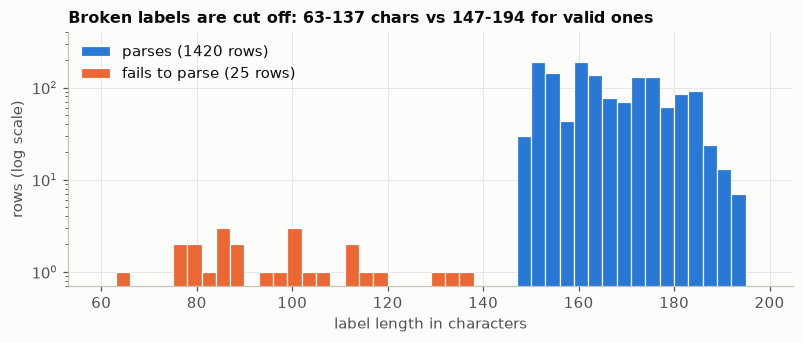

In [7]:
# 2.1 Why do 25 labels fail to parse?
bad = tr[~tr.parse_ok].copy()
def why(raw):
    try:
        json.loads(raw); return 'ok'
    except json.JSONDecodeError as e:
        return f'{e.msg} @ char {e.pos} of {len(raw)}'
bad['error'], bad['label_len'] = bad.label_raw.map(why), bad.label_raw.str.len()
print(bad[['id', 'label_len', 'error']].head(8).to_string(index=False), '\n...')
print('\nerror types:', bad.error.str.replace(r' @.*', '', regex=True).value_counts().to_dict())
show(tr, ids=bad.id.head(2).tolist())

good_len = tr[tr.parse_ok].label_raw.str.len()
fig, ax = plt.subplots(figsize=(8.5, 3))
bins = np.arange(60, 200, 3)
ax.hist(good_len, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.8, label=f'parses ({len(good_len)} rows)')
ax.hist(bad.label_len, bins=bins, color=ORANGE, edgecolor=SURFACE, linewidth=0.8, label=f'fails to parse ({len(bad)} rows)')
ax.set_yscale('log'); ax.set_ylim(0.7, 400)
ax.set_xlabel('label length in characters'); ax.set_ylabel('rows (log scale)'); ax.legend(loc='upper left')
ax.set_title(f'Broken labels are cut off: {bad.label_len.min()}-{bad.label_len.max()} chars vs '
             f'{good_len.min()}-{good_len.max()} for valid ones')
save(fig, 'fig2_truncated_labels')

In [8]:
# 2.2 Start the cleaning log. Drop the truncated rows, then check the drop does not skew the data.
CLEAN_LOG = []          # one dict per decision: id, action, reason
def log(ids, action, reason):
    assert action in ('drop', 'fix')
    for i in ids:
        CLEAN_LOG.append({'id': i, 'action': action, 'reason': reason})

log(bad.id, 'drop',
    'label JSON truncated (63-137 chars vs 147-194 normal); language/needs_human missing, not recoverable with certainty')

bad['cat_guess'] = bad.label_raw.str.extract(r'"category": "(\w+)"')[0]
good = tr[tr.parse_ok].copy()
good['category'] = good.label.map(lambda y: y.get('category'))
print(pd.DataFrame({'all_train_%': (good.category.value_counts(normalize=True) * 100).round(1),
                    'dropped_n': bad.cat_guess.value_counts()}).fillna(0))

                all_train_%  dropped_n
account_access         12.9          3
fraud                   6.4          1
kyc                    11.6          3
offers                 10.8          2
other                   7.2          2
payment_failed         29.2         11
refund                 22.0          3


**Decision: drop.** Every truncated label stops before `language`/`needs_human`, so the missing fields cannot be
filled with certainty, and guessing them would put invented labels into training. The 25 rows are spread across
categories; `payment_failed` is somewhat over-represented (11 of 25), but 25 rows are under 2% of train,
so the drop cannot move the label mix noticeably (Figure 6 in Section 9 confirms it).

## 3. Labels that break the output spec (70 + 30 + 20 rows fixed)

In [9]:
# 3.1 Check every parsed label against SCHEMA.md: keys, key order, enums, types, formats
KEYS = ['category', 'priority', 'amount_paise', 'txn_date', 'txn_id', 'channel', 'language', 'needs_human']
ENUMS = {'category': {'payment_failed', 'refund', 'fraud', 'account_access', 'kyc', 'offers', 'other'},
         'priority': {'P1', 'P2', 'P3'}, 'channel': {None, 'upi', 'card', 'netbanking', 'wallet'},
         'language': {'en', 'hi-en'}}

def violations(y):
    v = []                                          # list of (type, detail)
    if set(y) != set(KEYS):
        v.append(('keys', f'missing={sorted(set(KEYS) - set(y))} extra={sorted(set(y) - set(KEYS))}'))
    elif list(y) != KEYS:
        v.append(('key_order', str(list(y))))
    for k, allowed in ENUMS.items():
        if k in y and y[k] not in allowed:
            v.append((f'{k}_value', repr(y[k])))
    a = y.get('amount_paise')
    if a is not None and type(a) is not int:        # type(), not isinstance: bool is a subclass of int
        v.append(('amount_type', f'{type(a).__name__}: {a!r}'))
    d = y.get('txn_date')
    if d is not None and not (isinstance(d, str) and re.fullmatch(r'\d{4}-\d{2}-\d{2}', d)):
        v.append(('date_format', repr(d)))
    t = y.get('txn_id')
    if t is not None and not (isinstance(t, str) and re.fullmatch(r'NP\d{10}', t)):
        v.append(('txn_id_format', repr(t)))
    if 'needs_human' in y and type(y['needs_human']) is not bool:
        v.append(('needs_human_type', repr(y['needs_human'])))
    return v

for name, df in [('dev', dv), ('train', good)]:
    df = df.copy()
    df['viol'] = df.label.map(violations)
    ex = df.explode('viol').dropna(subset=['viol'])
    print(f'===== {name}: {df.viol.map(bool).sum()} of {len(df)} rows have >= 1 violation')
    for vt, g in ex.groupby(ex.viol.map(lambda t: t[0])):
        print(f'  [{vt}] {len(g)} rows | e.g. {g.viol.map(lambda t: t[1]).value_counts().head(4).to_dict()}')
    if name == 'train':
        good['viol'] = df.viol
good['vtypes'] = good.viol.map(lambda v: tuple(sorted({t for t, _ in v})))
print('\nwhich problems occur together:', good[good.vtypes != ()].vtypes.value_counts().to_dict())

===== dev: 0 of 200 rows have >= 1 violation
===== train: 90 of 1420 rows have >= 1 violation
  [date_format] 30 rows | e.g. {"'02/09/2026'": 2, "'10/09/2026'": 2, "'26/08/2026'": 1, "'29/07/2026'": 1}
  [keys] 70 rows | e.g. {"missing=['priority'] extra=['prio']": 70}
  [txn_id_format] 20 rows | e.g. {"'NP-9718716109'": 1, "'np9891267518'": 1, "'NP-2339259875'": 1, "'NP 9255627510'": 1}

which problems occur together: {('keys',): 40, ('date_format', 'keys'): 30, ('txn_id_format',): 20}


In [10]:
# 3.2 What does the legacy 'prio' contain? Compare it with SCHEMA.md's v2 priority rules, written as code.
LEGAL = re.compile(r'\b(rbi|ombudsman|consumer\s+court|lawyer|legal\s+(notice|action))\b', re.I)

def rule_priority(y, body):
    """SCHEMA.md v2 priority, applied in order. Amounts are in paise: Rs 50,000 = 50_000_00.
    A legal threat counts only in the customer's own words, not in a quoted earlier email."""
    c, a = y['category'], y['amount_paise']
    a = a if type(a) is int else None
    if c == 'fraud' or (a is not None and a >= 50_000_00) or LEGAL.search(first_part(body)):
        return 'P1'
    if (c in ('payment_failed', 'refund') and a is not None and a >= 5_000_00) or c == 'account_access':
        return 'P2'
    return 'P3'

pr = good[good.label.map(lambda y: 'prio' in y)].copy()
pr['prio_val'] = pr.label.map(lambda y: y['prio'])
pr['v2_rule']  = [rule_priority(y, b) for y, b in zip(pr.label, pr.body)]
print('prio values:', pr.prio_val.value_counts().to_dict(), '\n')
print('legacy prio (rows) vs v2 rule (cols):'); print(pd.crosstab(pr.prio_val, pr.v2_rule))

prio values: {'low': 44, 'medium': 15, 'high': 11} 

legacy prio (rows) vs v2 rule (cols):
v2_rule   P1  P2  P3
prio_val            
high      11   0   0
low        0   0  44
medium     0  15   0


**Decision: rename `prio` → `priority` with high/medium/low → P1/P2/P3.** The mapping agrees with the v2 rules
on all 70 rows, so it is a renamed key from an old schema version, not a different meaning.

In [11]:
# 3.3 Are the slash dates really DD/MM/YYYY (and not MM/DD)?
dd = good[good.vtypes.map(lambda t: 'date_format' in t)].copy()
dd['raw_date'] = dd.label.map(lambda y: y['txn_date'])
parts = dd.raw_date.str.extract(r'^(\d{2})/(\d{2})/(\d{4})$').astype(float)
print('match NN/NN/NNNN:', parts.notna().all(axis=1).sum(), 'of', len(dd))
print('first part > 12:', (parts[0] > 12).sum(), '| second part > 12:', (parts[1] > 12).sum())
dd['recv']    = pd.to_datetime(dd.received)
dd['as_ddmm'] = pd.to_datetime(dd.raw_date, format='%d/%m/%Y', errors='coerce')
dd['as_mmdd'] = pd.to_datetime(dd.raw_date, format='%m/%d/%Y', errors='coerce')
print('DD/MM reading: valid', dd.as_ddmm.notna().sum(), '| on/before Received', (dd.as_ddmm <= dd.recv).sum())
print('MM/DD reading: valid', dd.as_mmdd.notna().sum(), '| on/before Received', (dd.as_mmdd <= dd.recv).sum())
show(dd, ids=dd.id.head(2).tolist())

match NN/NN/NNNN: 30 of 30
first part > 12: 17 | second part > 12: 0
DD/MM reading: valid 30 | on/before Received 30
MM/DD reading: valid 13 | on/before Received 8
tr-00020 | 2026-09-05 Sat | ivr-transcript | 292 chars
[IVR transcript] Hey, How can I check if I have received a refund if it is not yet on my statement? 978 rupees is the amount. I have contacted support about this before. Mode: wallet. Using the Android app. This happened on 02-09-26. Thanks.
--> {"category": "refund", "prio": "low", "amount_paise": 97800, "txn_date": "02/09/2026", "txn_id": null, "channel": "wallet", "language": "en", "needs_human": true}
tr-00058 | 2026-09-13 Sun | ivr-transcript | 171 chars
[IVR transcript] Dear NimbusPay support, I tried to make a transfer and it didn't work. This happened on Aug 26. Thanks.
--> {"category": "payment_failed", "prio": "low", "amount_paise": null, "txn_date": "26/08/2026", "txn_id": null, "channel": null, "language": "en", "needs_human": false}


In [12]:
# 3.4 Non-normalised txn_ids: is the normalised id a valid NP+10 digits, and is it in the ticket text?
tt = good[good.vtypes.map(lambda t: 'txn_id_format' in t)].copy()
tt['raw_id']   = tt.label.map(lambda y: y['txn_id'])
tt['fixed_id'] = tt.raw_id.map(norm_id)
tt['valid']    = tt.fixed_id.str.fullmatch(r'NP\d{10}')
tt['in_text']  = [f in norm_id(b) for f, b in zip(tt.fixed_id, tt.body)]
print(f"{len(tt)} rows | valid after normalising: {tt.valid.sum()} | found in ticket text: {tt.in_text.sum()}")
print(tt[['id', 'raw_id', 'fixed_id']].head(6).to_string(index=False))

20 rows | valid after normalising: 20 | found in ticket text: 20
      id         raw_id     fixed_id
tr-00071  NP-9718716109 NP9718716109
tr-00147   np9891267518 NP9891267518
tr-00151  NP-2339259875 NP2339259875
tr-00391  NP 9255627510 NP9255627510
tr-00420 np 81633 47892 NP8163347892
tr-00460  NP 6949410784 NP6949410784


In [13]:
# 3.5 Apply the three format fixes to a working copy of the labels (the raw data stays untouched)
LAB = {i: dict(y) for i, y in zip(good.id, good.label)}

PRIO_MAP = {'high': 'P1', 'medium': 'P2', 'low': 'P3'}
ids = [i for i, y in LAB.items() if 'prio' in y]
for i in ids:
    LAB[i]['priority'] = PRIO_MAP[LAB[i].pop('prio')]
log(ids, 'fix', "legacy key 'prio' (low/medium/high) -> 'priority' (P3/P2/P1); mapping matches v2 rules on 70/70 rows")

ids = [i for i, y in LAB.items() if isinstance(y.get('txn_date'), str) and re.fullmatch(r'\d{2}/\d{2}/\d{4}', y['txn_date'])]
for i in ids:
    d, m, yr = LAB[i]['txn_date'].split('/')
    LAB[i]['txn_date'] = f'{yr}-{m}-{d}'
log(ids, 'fix', 'txn_date DD/MM/YYYY -> YYYY-MM-DD (DD/MM proven: 17 rows with day>12, 0 with month>12; all on/before Received)')

ids = [i for i, y in LAB.items() if isinstance(y.get('txn_id'), str) and not re.fullmatch(r'NP\d{10}', y['txn_id'])]
for i in ids:
    LAB[i]['txn_id'] = norm_id(LAB[i]['txn_id'])
log(ids, 'fix', 'txn_id normalised to NP+10 digits (uppercase, no spaces/hyphens); verified present in ticket text')

LAB = {i: {k: y[k] for k in KEYS} for i, y in LAB.items()}          # SCHEMA.md key order for every label
print('rows still violating the format:', sum(bool(violations(y)) for y in LAB.values()))
print('log so far:', pd.Series([e['action'] for e in CLEAN_LOG]).value_counts().to_dict())

rows still violating the format: 0
log so far: {'fix': 120, 'drop': 25}


## 4. Does each label's priority follow the v2 rules?

The rules are deterministic given category, amount and the ticket text, so any disagreement is either a wrong
label or a wrong input to the rule (category or amount). This section finds out which.

agreement: 95.4% | disagreements: 65

disagreements by category and direction (label -> rule):
change          P1 -> P3  P2 -> P3  P3 -> P1  P3 -> P2
category                                              
account_access         0         0         1         5
fraud                  0         0         4         0
kyc                    8         0         1         0
offers                 6         0         1         0
other                  2         0         1         0
payment_failed         9         1         6         5
refund                 8         2         1         4


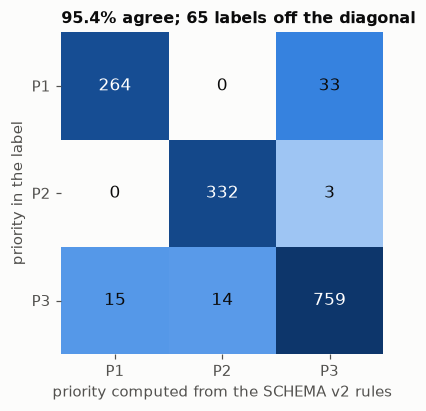

In [14]:
# 4.1 Agreement between the label's priority and the rules
chk = pd.DataFrame({'id': list(LAB)}).merge(tr[['id', 'body', 'source']], on='id')
chk['y']         = chk.id.map(LAB)
chk['category']  = chk.y.map(lambda y: y['category'])
chk['label_pri'] = chk.y.map(lambda y: y['priority'])
chk['rule_pri']  = [rule_priority(y, b) for y, b in zip(chk.y, chk.body)]
agree = (chk.label_pri == chk.rule_pri).mean()
mis = chk[chk.label_pri != chk.rule_pri].copy()
mis['change'] = mis.label_pri + ' -> ' + mis.rule_pri
print(f'agreement: {agree:.1%} | disagreements: {len(mis)}\n')
print('disagreements by category and direction (label -> rule):'); print(pd.crosstab(mis.category, mis.change))

P = ['P1', 'P2', 'P3']
ct = pd.crosstab(chk.label_pri, chk.rule_pri).reindex(index=P, columns=P, fill_value=0)
fig, ax = plt.subplots(figsize=(4.6, 3.8))
ax.imshow(np.ma.masked_equal(ct.values, 0), cmap=SEQ, norm=LogNorm(1, ct.values.max()))
for i in range(3):
    for j in range(3):
        v = ct.values[i, j]
        ax.text(j, i, f'{v}', ha='center', va='center', fontsize=11, color='white' if v > 100 else INK)
ax.set_xticks(range(3), P); ax.set_yticks(range(3), P); ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xlabel('priority computed from the SCHEMA v2 rules'); ax.set_ylabel('priority in the label')
ax.set_title(f'{agree:.1%} agree; {len(mis)} labels off the diagonal')
save(fig, 'fig3_priority_label_vs_rule')

In [15]:
# 4.2 Who is wrong, the label or the rule? needs_human is an independent witness:
#     SCHEMA.md says every P1 ticket needs a human, so a real P1 should have needs_human = true.
chk['nh'] = chk.y.map(lambda y: y['needs_human'])
mis['nh'] = mis.y.map(lambda y: y['needs_human'])
print('ALL rows: label priority vs needs_human'); print(pd.crosstab(chk.label_pri, chk.nh), '\n')
print('DISAGREEING rows: direction vs needs_human'); print(pd.crosstab(mis.change, mis.nh))

ALL rows: label priority vs needs_human
nh         False  True 
label_pri              
P1            30    267
P2           292     43
P3           675    113 

DISAGREEING rows: direction vs needs_human
nh        False  True 
change                
P1 -> P3     30      3
P2 -> P3      3      0
P3 -> P1      0     15
P3 -> P2     12      2


**Finding:** where the rule says P1 but the label says P3, `needs_human` is true on all of them, as it would be for a
real P1. Where the label says P1 and the rule says P3, `needs_human` is mostly false. So `needs_human` sides with the
rule: the priority labels are stale or noisy, not the rule. Before recomputing priorities, though, the rule's
inputs must be right, and the next cell shows they are not always.

In [16]:
# 4.3 Why does the rule say P1 where the label says P3? And a clue in two P1 -> P3 rows.
def rule_reason(y, body):
    c, a = y['category'], y['amount_paise']
    a = a if type(a) is int else None
    r = []
    if c == 'fraud': r.append('fraud')
    if a is not None and a >= 50_000_00: r.append(f'amount >= 50k (label says Rs {a/100:,.2f})')
    m = LEGAL.search(first_part(body))
    if m:
        r.append(f'legal word {m.group(0)!r}: "...{body[max(0, m.start() - 50):m.end() + 30]}..."')
    return ' | '.join(r)

for _, r in mis[mis.change == 'P3 -> P1'].iterrows():
    print(f'{r.id} [{r.category}]  ->  {rule_reason(r.y, r.body)}')

def show_lab(ids):
    for i in ids:
        r, y = tr.set_index('id').loc[i], LAB[i]
        a = y['amount_paise']
        print('=' * 100)
        print(f'{i} | {r.received} | {r.source} | label amount = ' + (f'{a} paise = Rs {a/100:,.2f}' if a is not None else 'null'))
        print(r.body)
        print('-->', json.dumps(y, ensure_ascii=False))

print('\n##### two P1 -> P3 rows: compare the label amount with the text')
show_lab(['tr-00073', 'tr-00187'])

tr-00045 [fraud]  ->  fraud
tr-00184 [kyc]  ->  legal word 'lawyer': "...Hey, The app doesn't know it's me. My lawyer will send a legal notice. My ..."
tr-00212 [payment_failed]  ->  amount >= 50k (label says Rs 110,000.00) | legal word 'RBI': "... phone is a Redmi Note 12. I will complain to the RBI ombudsman. The txn id is np 5..."
tr-00424 [payment_failed]  ->  legal word 'Consumer court': "... ne pasie kaat liye. 01-07-26 ki transaction hai. Consumer court jaunga. Transaction ID NP4498..."
tr-00427 [refund]  ->  amount >= 50k (label says Rs 274,981.00)
tr-00638 [fraud]  ->  fraud
tr-00852 [payment_failed]  ->  legal word 'Consumer court': "...on ID np5999441591 hai. Mera phone iPhone 13 hai. Consumer court jaunga. Please help karo...."
tr-00890 [payment_failed]  ->  legal word 'RBI': "...lue. ID: NP8302599992 I will escalate this to the RBI. Dated 5th August 2026. I am ..."
tr-01017 [offers]  ->  legal word 'consumer court': "...d points from the offer are missing. I will go to con

**Clue:** `tr-00073` says *Rs 1,68,787.25* but the label holds `168787`, i.e. the amount in **rupees**, not paise.
That hides a ≥ ₹50k amount, so the rule computes P3 instead of P1. Amounts need their own check (Section 5).
Priorities are recomputed only at the end (Section 8), after every input to the rule has been fixed.

## 5. Is the label amount the amount in the text? (25 fixed, 9 placeholder tickets dropped)

A parser finds every money mention (₹ / Rs / INR, *k*, *lakh(s)*, *rupees/rupaye*) and marks a mention as a
**distractor** when its *sentence* talks about a balance, limit or fee. A first version that looked at a fixed
45-character window, and counted the word "charge" as a distractor, wrongly flagged "I was charged twice for ₹X";
it also missed the plural "lakhs". Both were fixed by reading the rows it flagged.

In [17]:
# 5.1 Money parser (sentence-level distractors) and the per-row amount status
NUM = r'\d[\d,]*(?:\.\d+)?'
MONEY_PATS = [
    re.compile(rf'(?:₹|\brs\.?|\binr)\s*(?P<n>{NUM})\s*(?P<m>k|lakhs?|lacs?)?\b', re.I),   # ₹1,680 / Rs. 15.9k / INR 1 lakh
    re.compile(rf'(?P<n>{NUM})\s*(?P<m>k|lakhs?|lacs?)\b', re.I),                         # 4.7k / 2.6 lakhs
    re.compile(rf'(?P<n>{NUM})\s*(?:rupees|rupee|rupaye|rupay)\b', re.I),                  # 711 rupees / 4635 rupaye
]
DISTRACT = re.compile(r'balance|limit|\bfees?\b|pade hain|bacha|remaining', re.I)

def to_paise(n, m=None):
    v = float(n.replace(',', ''))
    if m: v *= 1_000 if m.lower() == 'k' else 1_00_000      # k / lakh / lakhs / lac / lacs
    return round(v * 100)

def boundaries(body):
    b = [-1]
    for m in re.finditer(r'[.!?](?=\s)|\n', body):
        if body[max(0, m.start() - 2):m.start()].lower() == 'rs':      # "Rs. 500" is not a sentence end
            continue
        b.append(m.start())
    b.append(len(body))
    return b

def sentence_of(body, s, e):
    b = boundaries(body)
    return body[max(x for x in b if x < s) + 1:min(x for x in b if x >= e) + 1].strip()

def money_mentions2(body):
    out = []
    for p in MONEY_PATS:
        for mt in p.finditer(body):
            try:
                paise = to_paise(mt.group('n'), mt.groupdict().get('m'))
            except ValueError:
                continue
            if any(o['paise'] == paise and abs(o['start'] - mt.start()) < 12 for o in out):
                continue                                             # same mention found by two patterns
            sent = sentence_of(body, mt.start(), mt.end())
            out.append(dict(paise=paise, start=mt.start(), sent=sent, distractor=bool(DISTRACT.search(sent))))
    return out

def amount_status2(y, body):
    a, ms = y['amount_paise'], money_mentions2(body)
    real = [m for m in ms if not m['distractor']]
    if a is None:
        if not ms: return 'null & no money'
        return 'null, only distractors' if not real else 'NULL BUT REAL AMOUNT'
    hit = [m for m in ms if m['paise'] == a]
    if hit:
        return 'match' if any(not m['distractor'] for m in hit) else 'TOOK DISTRACTOR'
    if any(a * 100 == m['paise'] or a == m['paise'] // 100 for m in ms):
        return 'RUPEES NOT CONVERTED'
    return 'NOT FOUND'

chk['amt2'] = [amount_status2(y, b) for y, b in zip(chk.y, chk.body)]
print(pd.crosstab(chk.category, chk.amt2, margins=True), '\n')
for st in ['null, only distractors', 'TOOK DISTRACTOR']:
    g = chk[chk.amt2 == st]
    print(f'##### {st}: {len(g)} rows')
    for _, r in g.head(3).iterrows():
        print(f'  {r.id} [{r.category}] label={r.y["amount_paise"]}')
        for m in money_mentions2(r.body):
            print(f'      {m["paise"]:>10}  distractor={m["distractor"]!s:5} | {m["sent"][:100]}')

amt2            NOT FOUND  RUPEES NOT CONVERTED  TOOK DISTRACTOR  match  null & no money  null, only distractors   All
category                                                                                                              
account_access          0                     0                0      0              183                       0   183
fraud                   0                     6                0     79                6                       0    91
kyc                     0                     0                0      0              165                       0   165
offers                  2                     2                0     78               71                       0   153
other                   0                     0                0      0              102                       0   102
payment_failed          2                     9                1    363               35                       4   414
refund                  3                     8 

**Finding:** 25 labels hold the amount in rupees (some also lost the decimals, e.g. ₹594.50 stored as `594`).
The 7 *null, only distractors* rows are labelled correctly: the ticket mentions only a balance or limit, so the
amount is null. The one *TOOK DISTRACTOR* row (`tr-00171`) is a limit of the parser, not of the label: in
"Amount: 62.3k FYI my daily limit is 27.7k" both numbers sit in one sentence, so the real amount inherits the
"limit" flag. The label (62.3k) is right.
The 7 `NOT FOUND` rows are not parser misses; the next cell shows what they are.

In [18]:
# 5.2 What are the NOT FOUND rows? -> placeholder tickets with fully populated labels. Search for all of them.
print(chk[chk.amt2 == 'NOT FOUND'][['id', 'body']].to_string(index=False), '\n')
JUNK = re.compile(r'^\s*(test|asdf|lorem|dummy|xxx|sample|hello)(\s+\w+){0,3}\s*$', re.I)
for name, df in [('train', tr), ('dev', dv), ('test', ts)]:
    b = df.body.str.strip()
    print(f'{name:5}: bodies under 30 chars: {(b.str.len() < 30).sum():2} | match JUNK: {b.str.match(JUNK).sum()} '
          f'| {b[b.str.len() < 30].value_counts().head(6).to_dict()}')

      id          body
tr-00034 test test 123
tr-00164          test
tr-00555 test test 123
tr-00790     asdf asdf
tr-00794 test test 123
tr-01032          test
tr-01166     asdf asdf 

train: bodies under 30 chars: 11 | match JUNK: 9 | {'test test 123': 3, 'test': 3, 'asdf asdf': 3, '': 1, 'URGENT!! I lost my password.': 1}
dev  : bodies under 30 chars:  0 | match JUNK: 0 | {}
test : bodies under 30 chars:  0 | match JUNK: 0 | {}


In [19]:
# 5.3 Apply: drop the placeholder tickets; re-derive the rupee amounts (only when exactly one mention fits)
junk_ids = tr[tr.body.str.strip().str.match(JUNK)].id.tolist()
log(junk_ids, 'drop', 'placeholder ticket text (e.g. "test", "asdf asdf") with a fully populated label; label not grounded in input')
DROPPED = {e['id'] for e in CLEAN_LOG if e['action'] == 'drop'}
chk = chk[~chk.id.isin(DROPPED)].copy()

fix_ids = []
for _, r in chk[chk.amt2 == 'RUPEES NOT CONVERTED'].iterrows():
    a = r.y['amount_paise']
    cands = {m['paise'] for m in money_mentions2(r.body) if a * 100 == m['paise'] or a == m['paise'] // 100}
    assert len(cands) == 1, (r.id, cands)              # refuse to guess if two mentions could match
    LAB[r.id]['amount_paise'] = new = cands.pop()
    fix_ids.append(r.id)
    if len(fix_ids) <= 6:
        print(f'{r.id}: {a} -> {new}   (Rs {new/100:,.2f})')
log(fix_ids, 'fix', 'amount_paise was in rupees (not x100; sometimes decimals dropped); re-derived from the amount stated in the ticket')

chk['y'] = chk.id.map(LAB)
chk['amt2'] = [amount_status2(y, b) for y, b in zip(chk.y, chk.body)]
print(f'... {len(fix_ids)} amounts fixed | junk dropped: {len(junk_ids)}')
print('amount status after fixes:', chk.amt2.value_counts().to_dict())

tr-00073: 168787 -> 16878725   (Rs 168,787.25)
tr-00144: 167 -> 16700   (Rs 167.00)
tr-00167: 267 -> 26700   (Rs 267.00)
tr-00187: 220000 -> 22000000   (Rs 220,000.00)
tr-00199: 674 -> 67400   (Rs 674.00)
tr-00222: 594 -> 59450   (Rs 594.50)
... 25 amounts fixed | junk dropped: 9
amount status after fixes: {'match': 816, 'null & no money': 587, 'null, only distractors': 7, 'TOOK DISTRACTOR': 1}


## 6. Duplicates and leakage (1 empty, 60 duplicates, 48 dev leaks, 40 near-duplicates dropped)

In [20]:
# 6.1 The empty ticket (header only, but with a full label)
empty = tr[tr.body.str.strip() == '']
for _, r in empty.iterrows():
    print(repr(r.id), repr(train[tr.index[tr.id == r.id][0]]['messages'][1]['content']), '-->', json.dumps(LAB.get(r.id)))
log(empty.id.tolist(), 'drop', 'empty ticket body (header only) with a populated label; label not grounded in input')
DROPPED = {e['id'] for e in CLEAN_LOG if e['action'] == 'drop'}

'tr-00318' 'Received: 2026-06-17 (Wed)\nSource: app-chat\n\n' --> {"category": "kyc", "priority": "P3", "amount_paise": null, "txn_date": null, "txn_id": null, "channel": null, "language": "hi-en", "needs_human": false}


In [21]:
# 6.2 Exact duplicates inside train, and train tickets copied from dev or test
user_of = {r['id']: r['messages'][1]['content'] for r in train}
live = tr[~tr.id.isin(DROPPED)].copy()
live['user'] = live.id.map(user_of)
live['lab_json'] = live.id.map(lambda i: json.dumps(LAB[i]))
full = [g for _, g in live.groupby('user') if len(g) > 1]
print(f'identical full tickets: {len(full)} groups, {sum(map(len, full))} rows | '
      f'groups whose labels DISAGREE: {sum(g.lab_json.nunique() > 1 for g in full)}')

def norm(s):
    return re.sub(r'\s+', ' ', s).strip().lower()
dev_full, test_full = {r['messages'][1]['content'] for r in dev}, {r['messages'][1]['content'] for r in test}
live['dev_full']  = live.user.isin(dev_full)
live['dev_body']  = live.body.map(norm).isin(set(dv.body.map(norm)))
live['test_full'] = live.user.isin(test_full)
live['test_body'] = live.body.map(norm).isin(set(ts.body.map(norm)))
print('train rows found in dev/test:', live[['dev_full', 'dev_body', 'test_full', 'test_body']].sum().to_dict())

dv_by_body = {norm(b): (i, rcv, lab) for i, b, rcv, lab in zip(dv.id, dv.body, dv.received, dv.label_raw)}
for _, r in live[live.dev_body].head(2).iterrows():
    di, drcv, dlab = dv_by_body[norm(r.body)]
    print('=' * 100)
    print(f'TRAIN {r.id} recv {r.received} | {r.lab_json}\nDEV   {di} recv {drcv} | {dlab}\n{r.body[:200]}')

identical full tickets: 60 groups, 120 rows | groups whose labels DISAGREE: 0


train rows found in dev/test: {'dev_full': 30, 'dev_body': 37, 'test_full': 0, 'test_body': 0}
TRAIN tr-00008 recv 2026-09-09 | {"category": "kyc", "priority": "P3", "amount_paise": null, "txn_date": null, "txn_id": null, "channel": null, "language": "en", "needs_human": false}
DEV   dv-00165 recv 2026-09-09 | {"category": "kyc", "priority": "P3", "amount_paise": null, "txn_date": null, "txn_id": null, "channel": null, "language": "en", "needs_human": false}
Hi team, What documents are required for proof of identity?
TRAIN tr-00086 recv 2026-06-02 | {"category": "kyc", "priority": "P3", "amount_paise": null, "txn_date": null, "txn_id": null, "channel": null, "language": "en", "needs_human": false}
DEV   dv-00064 recv 2026-06-02 | {"category": "kyc", "priority": "P3", "amount_paise": null, "txn_date": null, "txn_id": null, "channel": null, "language": "en", "needs_human": false}
Hi team, I am having difficulties to verify my identity. App version is 7.2.1. Kindly resolve this asap.


In [22]:
# 6.3 Apply: drop train rows whose body is a dev ticket (leakage), then the extra copies of exact duplicates
leak_ids = live[live.dev_body].id.tolist()
log(leak_ids, 'drop', 'ticket body identical to a dev ticket (leakage); dev rows must never be trained on')
DROPPED = {e['id'] for e in CLEAN_LOG if e['action'] == 'drop'}
n_dup = 0
for _, g in live[~live.id.isin(DROPPED)].groupby('user'):
    for i in g.id:
        if len(g) > 1 and i != g.id.min():
            log([i], 'drop', f'exact duplicate of {g.id.min()} (identical ticket and label)')
            n_dup += 1
DROPPED = {e['id'] for e in CLEAN_LOG if e['action'] == 'drop'}
print(f'dev leaks dropped: {len(leak_ids)} | duplicate copies dropped: {n_dup} | rows left: {len(tr) - len(DROPPED)}')

dev leaks dropped: 37 | duplicate copies dropped: 60 | rows left: 1313


Exact matching misses copies that differ only by whitespace, a greeting or a "Thx". A character n-gram TF-IDF
(3-5 chars) with cosine similarity catches those, both inside train and against dev.

In [23]:
# 6.4 Near-duplicates: train vs train, and each train row vs its closest dev ticket
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

cur = tr[~tr.id.isin(DROPPED)].copy()
cur['cat'] = cur.id.map(lambda i: LAB[i]['category'])
txt_tr, txt_dv = cur.body.map(first_part).tolist(), dv.body.map(first_part).tolist()
ids  = cur.id.tolist()
labs = [json.dumps(LAB[i]) for i in ids]
vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), sublinear_tf=True).fit(txt_tr + txt_dv)
A, B = vec.transform(txt_tr), vec.transform(txt_dv)

def diffs(a, b, k=4):
    sm = difflib.SequenceMatcher(None, a, b, autojunk=False)
    return [(a[i1:i2], b[j1:j2]) for op, i1, i2, j1, j2 in sm.get_opcodes() if op != 'equal'][:k]
bins = [0.85, 0.90, 0.95, 0.99, 1.0001]

S = cosine_similarity(A)
iu = np.triu_indices_from(S, k=1)
tt = pd.DataFrame({'i': iu[0], 'j': iu[1], 'sim': S[iu]})
tt = tt[tt.sim >= 0.85].copy()
tt['a'], tt['b'] = [ids[k] for k in tt.i], [ids[k] for k in tt.j]
tt['same_label'] = [labs[i] == labs[j] for i, j in zip(tt.i, tt.j)]
tt['bin'] = pd.cut(tt.sim, bins, right=False)
print('TRAIN-TRAIN pairs by similarity (same_label = share of pairs with identical labels):')
print(tt.groupby('bin', observed=False).agg(pairs=('sim', 'size'), same_label=('same_label', 'mean')).round(2))
for _, r in tt.sort_values('sim').groupby('bin', observed=True).head(1).iterrows():
    print(f"  e.g. {r.a} vs {r.b} sim={r.sim:.3f} same_label={r.same_label} diffs={diffs(txt_tr[r.i], txt_tr[r.j])}")

D = cosine_similarity(A, B)
td = pd.DataFrame({'id': ids, 'k': range(len(ids)), 'dk': D.argmax(1), 'sim': D.max(1)})
td['dev_id'] = dv.id.values[td.dk]
print('\nTRAIN rows by similarity to their closest DEV ticket:')
print(pd.cut(td.sim, bins, right=False).value_counts(sort=False).to_dict())
for _, r in td[td.sim >= 0.78].sort_values('sim', ascending=False).iterrows():
    print(f"  {r.id} ~ {r.dev_id}  sim={r.sim:.3f}  diffs={diffs(txt_tr[r.k], txt_dv[r.dk], 3)}")

TRAIN-TRAIN pairs by similarity (same_label = share of pairs with identical labels):
              pairs  same_label
bin                            
[0.85, 0.9)       7        0.71
[0.9, 0.95)       1        0.00
[0.95, 0.99)     10        1.00
[0.99, 1.0)      30        1.00
  e.g. tr-00120 vs tr-01400 sim=0.853 same_label=True diffs=[('[IVR transcript] ', ''), ('Android app use kar raha hoon. ', '')]
  e.g. tr-00954 vs tr-01164 sim=0.922 same_label=False diffs=[(' It was for Rs. 77.', '')]
  e.g. tr-00188 vs tr-01010 sim=0.971 same_label=True diffs=[('', ' '), ('', ' '), ('', ' Thx')]
  e.g. tr-00006 vs tr-00103 sim=0.990 same_label=True diffs=[('', ' '), ('', ' '), ('', ' '), ('', ' ')]

TRAIN rows by similarity to their closest DEV ticket:
{Interval(0.85, 0.9, closed='left'): 1, Interval(0.9, 0.95, closed='left'): 1, Interval(0.95, 0.99, closed='left'): 5, Interval(0.99, 1.0, closed='left'): 2}
  tr-00650 ~ dv-00178  sim=0.991  diffs=[(' ', ''), (' ', ''), (' ', '')]
  tr-01172 ~ d

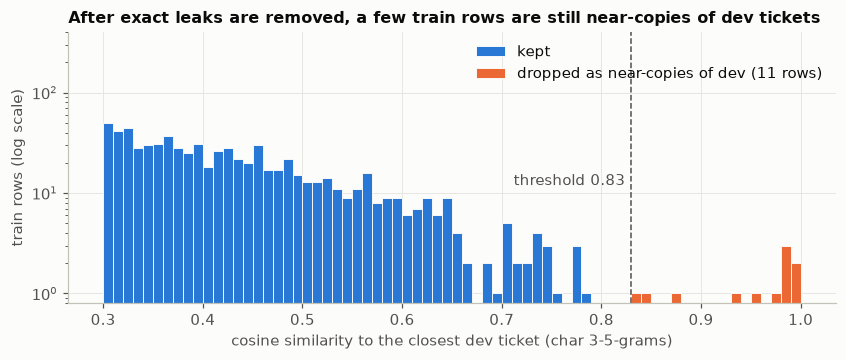

In [24]:
# 6.5 Where to put the leak threshold? Every train row's similarity to its closest dev ticket.
LEAK_T = 0.83
fig, ax = plt.subplots(figsize=(9, 3.2))
b = np.arange(0.30, 1.0001, 0.01)
ax.hist(td.sim[td.sim < LEAK_T], bins=b, color=BLUE, edgecolor=SURFACE, linewidth=0.6, label='kept')
ax.hist(td.sim[td.sim >= LEAK_T], bins=b, color=ORANGE, edgecolor=SURFACE, linewidth=0.6,
        label=f'dropped as near-copies of dev ({(td.sim >= LEAK_T).sum()} rows)')
ax.axvline(LEAK_T, color=INK2, lw=1, ls='--')
ax.set_yscale('log'); ax.set_ylim(0.8, 400)
ax.text(LEAK_T - 0.006, 12, f'threshold {LEAK_T}', ha='right', color=INK2)
ax.set_xlabel('cosine similarity to the closest dev ticket (char 3-5-grams)')
ax.set_ylabel('train rows (log scale)'); ax.legend(loc='upper right')
ax.set_title('After exact leaks are removed, a few train rows are still near-copies of dev tickets')
save(fig, 'fig4_train_dev_similarity')

**Decision.** The rows at ≥ 0.85 differ from their dev twin only by whitespace, "Thx" or filler. Reading the
0.78-0.85 band showed two more intent-only tickets (0.846, 0.833) that differ only by greeting/filler, while 0.78
is already a different ticket. So the leak threshold is **0.83**. Inside train, pairs at ≥ 0.95 always share the
label and differ only by whitespace/punctuation, so they are duplicates. Below 0.95 labels start to differ
(a different amount), so those pairs are distinct tickets and are kept.

In [25]:
# 6.6 Apply: near-leaks to dev first, then near-duplicates inside train (keep the lowest id of each group)
for _, r in td[td.sim >= 0.85].iterrows():
    log([r.id], 'drop', f"near-duplicate of dev ticket {r.dev_id} (char-ngram cosine {r.sim:.3f}; "
                        f"differs only by whitespace/'Thx'/filler); leakage")
for _, r in td[(td.sim >= LEAK_T) & (td.sim < 0.85)].iterrows():
    log([r.id], 'drop', f'near-duplicate of dev ticket {r.dev_id} (cosine {round(r.sim, 3)}; intent-only ticket differing only by '
                        f'greeting/filler; leak threshold 0.83 set by reading the 0.78-0.85 band)')
DROPPED = {e['id'] for e in CLEAN_LOG if e['action'] == 'drop'}

pairs = tt[(tt.sim >= 0.95) & ~tt.a.isin(DROPPED) & ~tt.b.isin(DROPPED)]
assert pairs.same_label.all(), 'a >= 0.95 pair with different labels: inspect before dropping'
parent = {i: i for i in ids}
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
for a, b in pairs[['a', 'b']].itertuples(index=False):                 # chains A~B~C form one group
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[max(ra, rb)] = min(ra, rb)
groups = collections.defaultdict(list)
for i in set(pairs.a) | set(pairs.b):
    groups[find(i)].append(i)
for root, members in groups.items():
    for m in members:
        if m != root:
            log([m], 'drop', f"near-duplicate of {root} (char-ngram cosine >= 0.95; differs only by "
                             f"whitespace/'Thx'/punctuation; identical label)")
DROPPED = {e['id'] for e in CLEAN_LOG if e['action'] == 'drop'}
cur = cur[~cur.id.isin(DROPPED)].copy()
print(f'near-leaks dropped: {(td.sim >= LEAK_T).sum()} | near-duplicate groups: {len(groups)} | rows left: {len(cur)}')

near-leaks dropped: 11 | near-duplicate groups: 40 | rows left: 1262


In [26]:
# 6.7 A last leak check by identity: does a train row share a transaction id, or intent + amount, with a dev ticket?
GREET = re.compile(
    r'^(?:@NimbusPayCare|\[IVR transcript\]|URGENT!+|Subject:[^\n]*|'
    r'(?:hi team|hi there|hi|hello ji|hello|hey|good morning|dear nimbuspay support|bhai|sir|namaste)\b,?)\s*', re.I)
def core(body):
    """The intent sentence: first sentence after greetings, without quotes and signature."""
    t = first_part(body)
    t = re.sub(r'\n\s*Regards,.*', '', t, flags=re.S).strip()
    prev = None
    while prev != t:
        prev, t = t, GREET.sub('', t, count=1).strip()
    m = re.match(r'(.+?[.?!])(?:\s|$)', t, re.S)
    return re.sub(r'\s+', ' ', m.group(1) if m else t).strip().lower()

NPID = re.compile(r'\bnp[\s\-]*\d(?:[\s\-]*\d){9}(?!\d)', re.I)          # NP + 10 digits, spaces/hyphens allowed
def ids_in_text(body):
    return {norm_id(m.group(0)) for m in NPID.finditer(first_part(body))}

dev_by_id, dev_by_core_amt = collections.defaultdict(set), collections.defaultdict(set)
for i, b in zip(dv.id, dv.body):
    for t in ids_in_text(b):
        dev_by_id[t].add(i)
    for m in money_mentions2(first_part(b)):
        dev_by_core_amt[(core(b), m['paise'])].add(i)
hits = [r.id for _, r in cur.iterrows()
        if any(t in dev_by_id for t in ids_in_text(r.body))
        or any((core(r.body), m['paise']) in dev_by_core_amt for m in money_mentions2(first_part(r.body)))]
print('train rows sharing a transaction id, or intent + amount, with a dev ticket:', len(hits))

train rows sharing a transaction id, or intent + amount, with a dev ticket: 0


## 7. Field-by-field checks on the remaining rows (no changes needed)

Each remaining field is checked against the ticket text. These checks found no errors, but they also settled
the conventions that train uses for ambiguous cases, which the model has to learn.

In [27]:
# 7.1 Category: is it consistent for the same intent sentence, and with fraud cues?
grp = cur.assign(core=cur.body.map(core)).groupby('core').agg(n=('id', 'size'), n_cat=('cat', 'nunique'),
                                                              cats=('cat', lambda s: s.value_counts().to_dict()))
print(f'distinct intent sentences: {len(grp)} | with more than one category: {(grp.n_cat > 1).sum()}')
print(grp[grp.n_cat > 1].to_string(), '\n')

FRAUD_CUE = re.compile(
    r"(did ?n['’]?t|did not|never) (make|made|authori[sz]e|do|approve)|"
    r"not (made|done|authori[sz]ed) by me|wasn['’]?t me|\bnot me\b|"
    r"(don['’]?t|do not|can['’]?t|cannot) recogni[sz]e|unrecogni[sz]ed|unauthori[sz]ed|"
    r"someone (else )?(has )?(used|stole|took|withdrew|is using)|stolen|hack|fraud|scam|"
    r"maine nahi kiya|maine nahi kiye|maine nahi ki|kisi ne|pata nahi kisne", re.I)
cur['fraud_cue'] = cur.body.map(lambda b: bool(FRAUD_CUE.search(first_part(b))))
print('explicit fraud cue (cols) by category (rows):'); print(pd.crosstab(cur.cat, cur.fraud_cue))

distinct intent sentences: 921 | with more than one category: 1
       n  n_cat                               cats
core                                              
help!  5      2  {'fraud': 3, 'account_access': 2} 

explicit fraud cue (cols) by category (rows):
fraud_cue       False  True 
cat                         
account_access    162      0
fraud              44     31
kyc               152      0
offers            132      0
other              89      0
payment_failed    372      0
refund            280      0


"Fraud wins over every other category": no ticket with an explicit fraud cue carries a non-fraud label. Fraud
tickets without a cue use softer wording ("unfamiliar payment", "cash withdrawal that isn't mine"), which is still fraud.
The only intent sentence with two categories is the bare "Help!", where the rest of the ticket decides.

In [28]:
# 7.2 Category: a cross-validated text classifier as a second opinion (reads the rows it disagrees with most)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.pipeline import make_pipeline, make_union

clf = make_pipeline(
    make_union(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
               TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2, sublinear_tf=True)),
    LogisticRegression(max_iter=3000, C=10))
X, y = cur.body.map(first_part), cur.cat.values
proba = cross_val_predict(clf, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), method='predict_proba')
classes = np.unique(y)
cur['pred'], cur['p_label'] = classes[proba.argmax(1)], proba[np.arange(len(y)), np.searchsorted(classes, y)]
sus = cur[cur.pred != cur.cat].sort_values('p_label')
print(f'cross-validated accuracy: {(cur.pred == cur.cat).mean():.1%} | disagreements: {len(sus)}\n')
print('disagreements, label -> prediction:', sus.groupby(['cat', 'pred']).size().sort_values(ascending=False).to_dict(), '\n')
for _, r in sus.head(8).iterrows():
    print(f"  {r.id} label={r['cat']:15} pred={r.pred:15} p_label={r.p_label:.2f} | {first_part(r.body)[:110]!r}")

cross-validated accuracy: 97.0% | disagreements: 38

disagreements, label -> prediction: {('fraud', 'payment_failed'): 12, ('fraud', 'refund'): 10, ('other', 'account_access'): 7, ('account_access', 'other'): 2, ('kyc', 'other'): 2, ('refund', 'payment_failed'): 2, ('fraud', 'offers'): 1, ('kyc', 'account_access'): 1, ('payment_failed', 'other'): 1} 

  tr-01333 label=fraud           pred=refund          p_label=0.07 | 'Subject: Problem with NimbusPay\n\nHello,\nI have a charge I did not make. Transaction ID np4076009763. It took p'
  tr-01128 label=other           pred=account_access  p_label=0.09 | 'Subject: Complaint\n\nGood morning,\ncan i create my own pin right away. I am on the iOS app. My earlier ticket n'
  tr-00206 label=fraud           pred=payment_failed  p_label=0.09 | 'URGENT!! my statement contains an unknown payment. Amount: Rs. 49474 Transaction date 11th August 2026. Mode: '
  tr-01286 label=account_access  pred=other           p_label=0.09 | "[IVR transcript] Hi team

**Finding:** reading the disagreements, the labels are defensible. Most are fraud tickets that the bag-of-words
model calls `payment_failed`/`refund` because the fraud wording is soft, and "card frozen / reset PIN" tickets
on the `account_access`/`other` border. No category was changed: a 97%-accurate classifier is not evidence
strong enough to overrule a label, and the rule "fraud wins" is applied consistently.

In [29]:
# 7.3 txn_id: is every labelled id in the text, and every id in the text in the label?
#     Also: transaction fields must be null for account_access, kyc and other.
def txn_status(y, body):
    lab, found = y['txn_id'], ids_in_text(body)
    if lab is None:
        return 'null & none in text' if not found else 'NULL BUT ID IN TEXT'
    if lab in found:
        return 'match' if len(found) == 1 else 'match (text has several ids)'
    return 'LABEL ID NOT IN TEXT'

cur['txn_st'] = [txn_status(LAB[i], b) for i, b in zip(cur.id, cur.body)]
print(pd.crosstab(cur.cat, cur.txn_st, margins=True), '\n')
NON_TXN, TXN_F = {'account_access', 'kyc', 'other'}, ['amount_paise', 'txn_date', 'txn_id', 'channel']
TXN_CATS = {'payment_failed', 'refund', 'fraud', 'offers'}
print('non-transaction rows with a non-null transaction field:',
      sum(LAB[i]['category'] in NON_TXN and any(LAB[i][k] is not None for k in TXN_F) for i in cur.id))

txn_st          match  null & none in text   All
cat                                             
account_access      0                  162   162
fraud              38                   37    75
kyc                 0                  152   152
offers              0                  132   132
other               0                   89    89
payment_failed    221                  151   372
refund            158                  122   280
All               417                  845  1262 

non-transaction rows with a non-null transaction field: 0


In [30]:
# 7.4 Channel: does the label match the channel words in the text?
CHAN_CUES = {'upi': re.compile(r'\bupi\b', re.I), 'netbanking': re.compile(r'net\s*-?\s*banking|internet\s+banking', re.I),
             'wallet': re.compile(r'\bwallet\b', re.I), 'card': re.compile(r'\bcard\b|\bvisa\b|master\s*card', re.I)}
cc = cur[cur.cat.isin(TXN_CATS)].copy()
cc['ch_label'] = cc.id.map(lambda i: LAB[i]['channel'] or 'null')
cc['ch_text']  = cc.body.map(lambda b: '+'.join(sorted(k for k, p in CHAN_CUES.items() if p.search(first_part(b)))) or 'none')
print('rows = channel words found in the text, cols = label channel'); print(pd.crosstab(cc.ch_text, cc.ch_label), '\n')
sc = cc[(cc.ch_text == 'card') & (cc.ch_label == 'null')]
print(f'"card" in the text but channel null: {len(sc)} rows | all mention a scratch card:',
      sc.body.str.contains(r'scr?a?tch|srcatch', case=False).sum() == len(sc))

rows = channel words found in the text, cols = label channel
ch_label         card  netbanking  null  upi  wallet
ch_text                                             
card              206           0    23    0       0
card+netbanking     0           1     0    0       0
card+upi            0           0     0    2       0
netbanking          0         124     0    0       0
none                0           0   321    0       0
upi                 0           0     0  107       0
wallet              0           0     0    0      75 

"card" in the text but channel null: 23 rows | all mention a scratch card: True


**Convention:** a *scratch card* (a reward) is not a payment channel, so channel stays null. Where two channel
words appear, the label takes the one the payment used.

In [31]:
# 7.5 txn_date: resolve every date in the text (absolute and relative to Received) and compare with the label
MONTHS = {m: i for i, m in enumerate(['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec'], 1)}
MON = r'(jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec)[a-z]*\.?'
DATE_PATS = [
    ('dmy', re.compile(r'\b(\d{1,2})[/-](\d{1,2})[/-](\d{4}|\d{2})\b')),                           # 28-06-26, 21/05/2026
    ('d_mon', re.compile(rf'\b(\d{{1,2}})(?:st|nd|rd|th)?\s+{MON}(?:,?\s+(\d{{4}}))?', re.I)),    # 5th August 2026, 16 May
    ('mon_d', re.compile(rf'\b{MON}\s+(\d{{1,2}})(?:st|nd|rd|th)?\b(?:,?\s+(\d{{4}}))?', re.I)),  # Aug 26
]
REL = [   # order matters: 'day before yesterday' must be consumed before 'yesterday'
    (re.compile(r'\bday before yesterday\b|\bparso\b', re.I), 2), (re.compile(r'\byesterday\b|\bkal\b', re.I), 1),
    (re.compile(r'\btoday\b|\baaj\b', re.I), 0), (re.compile(r'\b(\d+)\s+days?\s+ago\b', re.I), 'n'),
    (re.compile(r'\b(\d+)\s+din\s+pehle\b', re.I), 'n')]

def dates_in_text(body, received):
    t, R, out = first_part(body), dt.date.fromisoformat(received), set()
    for name, p in DATE_PATS:
        for m in p.finditer(t):
            try:
                if name == 'dmy':
                    d, mo, yy = map(int, m.groups())
                    out.add(dt.date(yy + 2000 if yy < 100 else yy, mo, d))
                else:
                    g = m.groups()
                    d, mon, yy = (g[0], g[1], g[2]) if name == 'd_mon' else (g[1], g[0], g[2])
                    mo, d = MONTHS[mon.lower()[:3]], int(d)
                    if yy:
                        out.add(dt.date(int(yy), mo, d))
                    else:                                   # no year -> the most recent such date on/before Received
                        c = dt.date(R.year, mo, d)
                        out.add(c if c <= R else dt.date(R.year - 1, mo, d))
            except ValueError:
                pass
    for p, k in REL:
        for m in p.finditer(t):
            out.add(R - dt.timedelta(days=int(m.group(1)) if k == 'n' else k))
        t = p.sub(' ', t)
    return {d.isoformat() for d in out}

def date_status(y, body, received):
    lab, found = y['txn_date'], dates_in_text(body, received)
    if lab is None:
        return 'null & no date' if not found else 'NULL BUT DATE IN TEXT'
    if lab > received:
        return 'LABEL AFTER RECEIVED'
    if lab in found:
        return 'match' if len(found) == 1 else 'match (several dates)'
    return 'MISMATCH' if found else 'LABEL DATE, NONE FOUND'

cur['date_st'] = [date_status(LAB[i], b, rc) for i, b, rc in zip(cur.id, cur.body, cur.received)]
print(pd.crosstab(cur.cat, cur.date_st, margins=True), '\n')
for _, r in cur[cur.date_st.isin(['MISMATCH', 'match (several dates)'])].iterrows():
    print(f"  {r.id} [{r.date_st}] label={LAB[r.id]['txn_date']} found={sorted(dates_in_text(r.body, r.received))}"
          f" | {first_part(r.body)[:120]!r}")

date_st         MISMATCH  match  match (several dates)  null & no date   All
cat                                                                         
account_access         0      0                      0             162   162
fraud                  1     56                      0              18    75
kyc                    0      0                      0             152   152
offers                 0     28                      0             104   132
other                  0      0                      0              89    89
payment_failed         0    268                      0             104   372
refund                 0    208                      1              71   280
All                    1    560                      1             700  1262 

  tr-00998 [MISMATCH] label=2026-06-14 found=['2674-06-14'] | 'Hey, i dont recognize a charge on my card. Transaction date 14 Jun. 2674 rupees is the amount. Transaction reference NP-'
  tr-01098 [match (several dates)] label=20

The single `MISMATCH` is the parser, not the label: "14 Jun. 2674 rupees" reads as the year 2674. Dates without
a year resolve to the most recent such date on or before Received, and relative dates count back from Received.

In [32]:
# 7.6 needs_human: what counts as "contacted before"?
PRIOR_EXPLICIT = re.compile(
    r"(third|second|fourth|fifth|\d+(st|nd|rd|th)?) time I|again and again|"
    r"contacted (support|you) about this before|already (written|contacted|complained|raised|reported)|"
    r"written \d+ times|second complaint|keep raising|"
    r"baar baar|pehle bhi|teesri baar|dusri baar|doosri baar|kitni baar|phir se complaint", re.I)
EARLIER_TICKET = re.compile(r'earlier ticket|ticket (number|no)', re.I)

cur['rule_p1']   = [rule_priority(LAB[i], b) == 'P1' for i, b in zip(cur.id, cur.body)]
cur['nh']        = cur.id.map(lambda i: LAB[i]['needs_human'])
cur['explicit']  = cur.body.map(lambda b: bool(PRIOR_EXPLICIT.search(first_part(b))))
cur['earlier_t'] = cur.body.map(lambda b: bool(EARLIER_TICKET.search(first_part(b))))
cur['quoted']    = cur.body.str.contains(r'^>', regex=True, flags=re.M)
print('P1 rows: needs_human =', cur[cur.rule_p1].nh.value_counts().to_dict(), '\n')
np1 = cur[~cur.rule_p1]
print('NON-P1 rows: needs_human by evidence of prior contact')
print(pd.crosstab([np1.explicit, np1.earlier_t, np1.quoted], np1.nh))

P1 rows: needs_human =

 {True: 243} 



NON-P1 rows: needs_human by evidence of prior contact
nh                         False  True 
explicit earlier_t quoted              
False    False     False     821      0
                   True       19      0
         True      False      54      0
                   True        1      0
True     False     False       0    119
                   True        0      2
         True      False       0      2
                   True        0      1


**Convention (settled from train, every row agrees):** `needs_human = true` exactly when the ticket is P1 or the
customer **says** they contacted support before ("third time", *pehle bhi*, *teesri baar*). Merely quoting an
earlier ticket number, or an email that contains quoted earlier replies, does **not** count.

In [33]:
# 7.7 language: count Hindi content words in the customer's own text
HI_WORDS = set("""hai hain nahi nahin kar karo karna kiya kiye raha rahi rahe hoon hun mera mere meri mujhe
ka ki ke ko se hua hui hue tha thi paise paisa kya kyun kyon abhi pehle baar wapas jaldi gaye gaya gayi
diya liya kat kaat dikh dikha bol bata batao chahiye lekin aur par mein yeh woh ek kal parso din
rupaye rakam ab tak mila mile mili hota hoga""".split())       # no 'the', 'do', 'to': they collide with English
HI_GREET = {'namaste', 'ji', 'bhai', 'dhanyavaad', 'shukriya'}

def hi_counts(body):
    t = re.sub(r'\n\s*Regards,.*', '', first_part(body), flags=re.S)
    toks = re.findall(r'[a-z]+', t.lower())
    return sum(w in HI_WORDS for w in toks), sum(w in HI_GREET for w in toks)

cur[['hi_n', 'hi_greet']] = pd.DataFrame([hi_counts(b) for b in cur.body], index=cur.index)
cur['lang'] = cur.id.map(lambda i: LAB[i]['language'])
print('Hindi content words (rows) vs language label (cols):')
print(pd.crosstab(pd.cut(cur.hi_n, [-1, 0, 1, 2, 5, 999], labels=['0', '1', '2', '3-5', '6+']), cur.lang), '\n')
for _, r in cur[(cur.lang == 'hi-en') & (cur.hi_n <= 1)].iterrows():
    print(f'  {r.id} lang={r.lang} hi_n={r.hi_n} | {first_part(r.body)[:110]!r}')
for name, df in [('dev', dv), ('test', ts)]:
    h = pd.DataFrame([hi_counts(b) for b in df.body], columns=['hi_n', 'hi_greet'])
    print(f'{name}: Hindi greeting but 0-1 Hindi content words: {((h.hi_greet > 0) & (h.hi_n <= 1)).sum()} of {len(df)}')

Hindi content words (rows) vs language label (cols):


lang   en  hi-en
hi_n            
0     902      1
1       1      1
2       0      4
3-5     0     38
6+      0    315 

  tr-00049 lang=hi-en hi_n=0 | '[IVR transcript]  Regsitered email id kaise change karun? Dhanyavaad.'
  tr-01228 lang=hi-en hi_n=1 | 'Hello ji, Registered email id kaise change karun? Bank ref 788380775008 hai. Dhanyavaad.'
dev: Hindi greeting but 0-1 Hindi content words: 0 of 200
test: Hindi greeting but 0-1 Hindi content words: 0 of 400


The two `hi-en` rows with ≤ 1 counted word are real Hinglish (*kaise change karun*) that the word list does not
cover, so the labels are right. The pattern does not occur in dev or test.

## 8. Recompute priority with the v2 rules (60 fixed)

All inputs to the rule are now fixed (amounts re-derived, junk and duplicates gone), so the rule is applied to
every kept row. Section 4 showed that `needs_human` sides with the rule, so these are label corrections.

In [34]:
def pri_reason(y, body):
    c, a = y['category'], y['amount_paise']
    a = a if type(a) is int else None
    if c == 'fraud':                     return 'category fraud'
    if a is not None and a >= 50_000_00: return 'amount >= Rs 50,000'
    m = LEGAL.search(first_part(body))
    if m:                                return f'legal threat ({m.group(0)!r})'
    if c == 'account_access':            return 'category account_access'
    if c in ('payment_failed', 'refund') and a is not None and a >= 5_000_00:
                                         return f'{c} with amount >= Rs 5,000'
    return 'no P1/P2 condition met'

body_of = dict(zip(cur.id, cur.body))
changes = [(i, LAB[i]['priority'], rule_priority(LAB[i], body_of[i]), pri_reason(LAB[i], body_of[i]))
           for i in cur.id if LAB[i]['priority'] != rule_priority(LAB[i], body_of[i])]
print('priority changes:', len(changes))
print(dict(collections.Counter(f'{a} -> {b}' for _, a, b, _ in changes)))
print(dict(collections.Counter(r for *_, r in changes)))
for i, old, new, why in changes:
    LAB[i]['priority'] = new
    log([i], 'fix', f'priority {old} -> {new} per SCHEMA v2 rules ({why})')

priority changes: 60
{'P1 -> P3': 31, 'P3 -> P1': 15, 'P3 -> P2': 14}
{'no P1/P2 condition met': 31, 'category fraud': 4, 'payment_failed with amount >= Rs 5,000': 5, "legal threat ('lawyer')": 1, 'amount >= Rs 50,000': 4, 'refund with amount >= Rs 5,000': 4, 'category account_access': 5, "legal threat ('Consumer court')": 3, "legal threat ('RBI')": 1, "legal threat ('consumer court')": 2}


## 9. Final validation gate and export

In [35]:
# 9.1 Every rule on every kept row. The export only happens if nothing fails.
DROPPED  = {e['id'] for e in CLEAN_LOG if e['action'] == 'drop'}
keep_ids = [r['id'] for r in train if r['id'] not in DROPPED]
body_of, recv_of = dict(zip(tr.id, tr.body)), dict(zip(tr.id, tr.received))

problems = collections.Counter()
for i in keep_ids:
    y, b, rc = LAB[i], body_of[i], recv_of[i]
    if violations(y):                                problems['format'] += 1
    if list(y) != KEYS:                              problems['key_order'] += 1
    if y['priority'] != rule_priority(y, b):         problems['priority_rule'] += 1
    if y['needs_human'] != (y['priority'] == 'P1' or bool(PRIOR_EXPLICIT.search(first_part(b)))):
                                                     problems['needs_human_rule'] += 1
    if y['category'] in NON_TXN and any(y[k] is not None for k in TXN_F):
                                                     problems['txn_fields_not_null'] += 1
    if y['category'] in TXN_CATS:
        if amount_status2(y, b) in ('NOT FOUND', 'RUPEES NOT CONVERTED', 'NULL BUT REAL AMOUNT'):
                                                     problems['amount'] += 1
        if txn_status(y, b) in ('NULL BUT ID IN TEXT', 'LABEL ID NOT IN TEXT'):
                                                     problems['txn_id'] += 1
        if date_status(y, b, rc) in ('LABEL AFTER RECEIVED', 'NULL BUT DATE IN TEXT', 'LABEL DATE, NONE FOUND'):
                                                     problems['txn_date'] += 1
    if user_of[i] in dev_full:                       problems['dev_overlap'] += 1

print('rows kept:', len(keep_ids), '(expected 1262) | problems:', dict(problems) or 'NONE')
assert len(keep_ids) == 1262 and not problems

rows kept: 1262 (expected 1262) | problems: NONE


In [36]:
# 9.2 Export train_clean.jsonl and cleaning_log.csv
for r in dev:                      # labels must be serialised exactly like dev (key order, spacing, ensure_ascii)
    s = r['messages'][-1]['content']
    assert s == json.dumps(json.loads(s), ensure_ascii=False), 'dev uses a different serialisation!'

with open(f'{OUT}/train_clean.jsonl', 'w', encoding='utf-8') as f:   # original order; system + user unchanged
    for r in train:
        if r['id'] in DROPPED:
            continue
        f.write(json.dumps({'id': r['id'], 'messages': [
            r['messages'][0], r['messages'][1],
            {'role': 'assistant', 'content': json.dumps(LAB[r['id']], ensure_ascii=False)}]}, ensure_ascii=False) + '\n')

by_id = collections.defaultdict(list)          # one line per id; a dropped row lists only its drop reason
for e in CLEAN_LOG:
    by_id[e['id']].append(e)
rows = []
for i in sorted(by_id):
    drops = [e['reason'] for e in by_id[i] if e['action'] == 'drop']
    reasons = drops or [e['reason'] for e in by_id[i]]
    rows.append({'id': i, 'action': 'drop' if drops else 'fix', 'reason': ' | '.join(dict.fromkeys(reasons))})
pd.DataFrame(rows).to_csv(f'{OUT}/cleaning_log.csv', index=False, quoting=csv.QUOTE_MINIMAL)
print('cleaning_log.csv lines:', len(rows), '| drop:', sum(r['action'] == 'drop' for r in rows),
      '| fix:', sum(r['action'] == 'fix' for r in rows), '| field fixes:', sum(e['action'] == 'fix' for e in CLEAN_LOG))

cleaning_log.csv lines: 358 | drop: 183 | fix: 175 | field fixes: 205


action  kind               
drop    dev leak               48
        exact duplicate        60
        junk / empty ticket    10
        near-duplicate         40
        truncated JSON         25
fix     amount in rupees       25
        legacy prio key        70
        priority rule          60
        txn_date DD/MM         30
        txn_id format          20


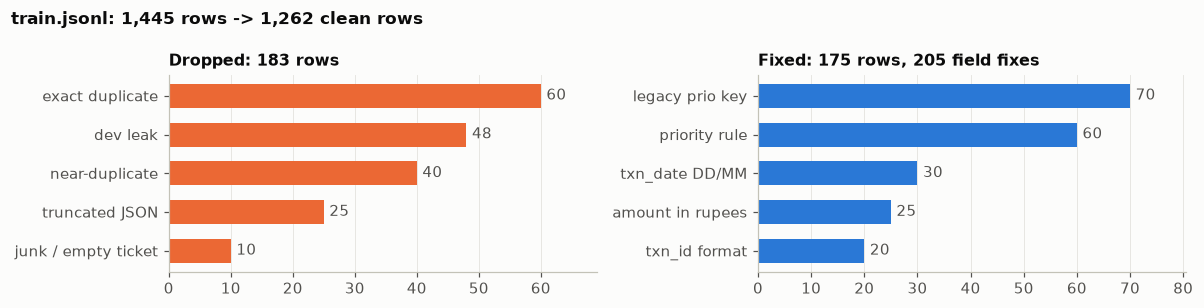

In [37]:
# 9.3 Summary of every decision
def kind(reason):
    for k, pat in [('truncated JSON', 'truncated'), ('junk / empty ticket', 'placeholder|empty ticket'),
                   ('dev leak', 'dev ticket|identical to a dev'), ('exact duplicate', 'exact duplicate'),
                   ('near-duplicate', 'near-duplicate of tr'), ('legacy prio key', 'legacy key'),
                   ('txn_date DD/MM', 'txn_date'), ('txn_id format', 'txn_id normalised'),
                   ('amount in rupees', 'amount_paise'), ('priority rule', 'priority ')]:
        if re.search(pat, reason):
            return k
    return 'other'

log_df = pd.DataFrame(CLEAN_LOG)
log_df['kind'] = log_df.reason.map(kind)
summ = log_df.groupby(['action', 'kind']).size()
print(summ.to_string())

n_drop = log_df[log_df.action == 'drop'].id.nunique()
n_fix_rows = log_df[(log_df.action == 'fix') & ~log_df.id.isin(DROPPED)].id.nunique()
fig, axes = plt.subplots(1, 2, figsize=(11, 2.8))
for ax, act, col, title in [(axes[0], 'drop', ORANGE, f'Dropped: {n_drop} rows'),
                            (axes[1], 'fix', BLUE, f'Fixed: {n_fix_rows} rows, {int(summ["fix"].sum())} field fixes')]:
    s = summ[act].sort_values()
    ax.barh(s.index, s.values, color=col, height=0.62)
    for k, v in enumerate(s.values):
        ax.text(v + s.max() * 0.015, k, str(v), va='center', color=INK2)
    ax.set_xlim(0, s.max() * 1.15); ax.grid(axis='y', visible=False); ax.set_title(title)
fig.suptitle(f'train.jsonl: {len(train):,} rows -> {len(keep_ids):,} clean rows', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
save(fig, 'fig5_cleaning_summary')

--- category (%)
                raw train  clean train   dev
account_access       12.9         12.8   9.5
fraud                 6.4          5.9   7.5
kyc                  11.6         12.0  12.0
offers               10.8         10.5   9.0
other                 7.2          7.1   8.0
payment_failed       29.2         29.5  26.5
refund               22.0         22.2  27.5

--- priority (%)
    raw train  clean train   dev
P3       55.5         56.1  53.0
P2       23.6         24.6  26.0
P1       20.9         19.3  21.0

--- language (%) clean train: {'en': 71.6, 'hi-en': 28.4} | dev: {'en': 75.5, 'hi-en': 24.5}
--- needs_human (%) clean train: {False: 70.9, True: 29.1} | dev: {False: 69.5, True: 30.5}


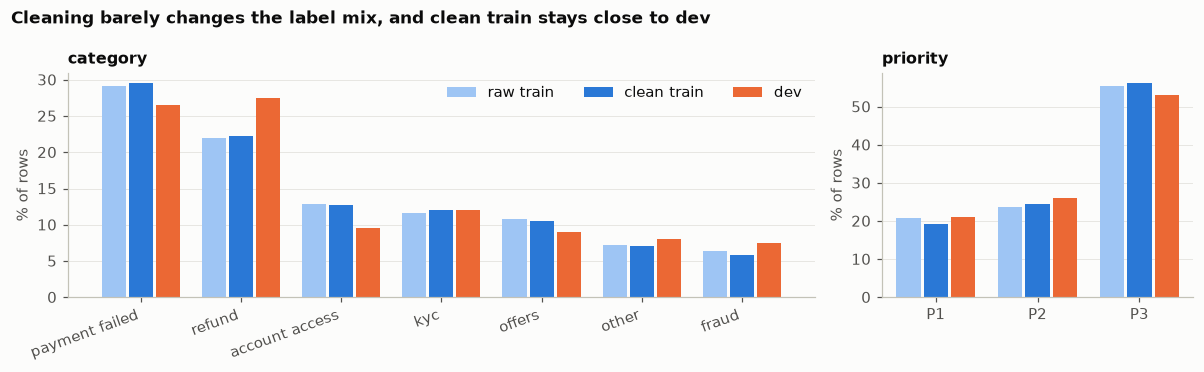

In [38]:
# 9.4 Did cleaning change the label distributions? (descriptive only; dev is shown for comparison, never used to clean)
clean_labels = [LAB[i] for i in keep_ids]
raw_pri = lambda y: y.get('priority') or PRIO_MAP.get(y.get('prio'))          # legacy 'prio' mapped, for comparison
dists = {}
for key in ['category', 'priority']:
    get = raw_pri if key == 'priority' else (lambda y: y[key])
    dists[key] = pd.DataFrame({
        'raw train':   pd.Series([get(y) for y in good.label]).value_counts(normalize=True),
        'clean train': pd.Series([y[key] for y in clean_labels]).value_counts(normalize=True),
        'dev':         pd.Series([y[key] for y in dv.label]).value_counts(normalize=True)}).mul(100).round(1)
    print(f'--- {key} (%)\n{dists[key]}\n')
for key in ['language', 'needs_human']:
    print(f'--- {key} (%) clean train:', pd.Series([y[key] for y in clean_labels]).value_counts(normalize=True).mul(100).round(1).to_dict(),
          '| dev:', pd.Series([y[key] for y in dv.label]).value_counts(normalize=True).mul(100).round(1).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={'width_ratios': [2.4, 1]})
colors = {'raw train': LIGHT_BLUE, 'clean train': BLUE, 'dev': ORANGE}
for ax, key in zip(axes, ['category', 'priority']):
    t = dists[key].sort_values('clean train', ascending=False) if key == 'category' else dists[key].sort_index()
    x, w = np.arange(len(t)), 0.27
    for k, c in enumerate(t.columns):
        ax.bar(x + (k - 1) * w, t[c], width=w - 0.03, color=colors[c], label=c)
    ax.set_xticks(x, [s.replace('_', ' ') for s in t.index], rotation=0 if key == 'priority' else 20, ha='center' if key == 'priority' else 'right')
    ax.set_ylabel('% of rows'); ax.grid(axis='x', visible=False); ax.set_title(key)
axes[0].legend(ncols=3)
fig.suptitle('Cleaning barely changes the label mix, and clean train stays close to dev', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
save(fig, 'fig6_label_distributions')